# Workshop 2 — Displaying Multivariate Data in Python

Original lab charts from the workshop instructions. The solution for each exercise is in the code cell directly below that chart.


In [1]:
import matplotlib.pyplot as plt
import matplotlib.cm
import seaborn as sns
import pandas as pd
from pandas.plotting import parallel_coordinates
from ChernoffFace import *
import numpy as np


##### Basic Scatter Plot


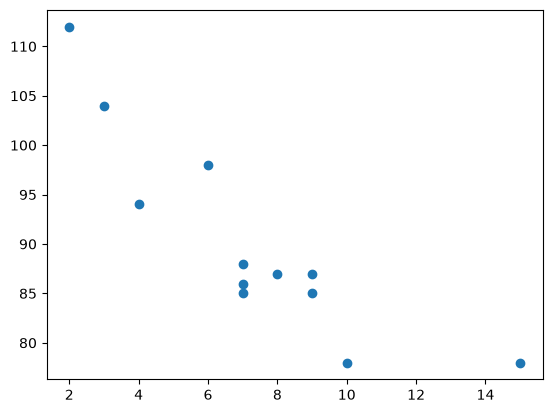

In [2]:
# Define the data
x = [6, 7, 8, 7, 2, 3, 9, 4, 10, 15, 9, 7]
y = [98, 85, 87, 88, 112, 104, 87, 94, 78, 78, 85, 86]

# Create the scatter plot
plt.scatter(x, y)

# Display the plot
plt.show()


**Plot 1:** Add x label as "Hours Studied" and y label as "Exam Score", and change the point colour to red


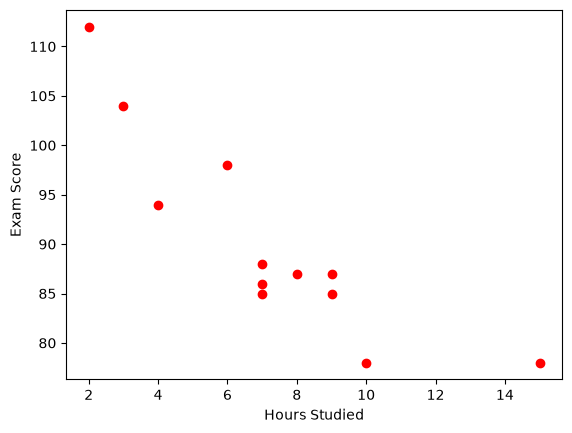

In [3]:
plt.scatter(x, y, color="red")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.show()


##### Scatter Plot with Multiple Classes


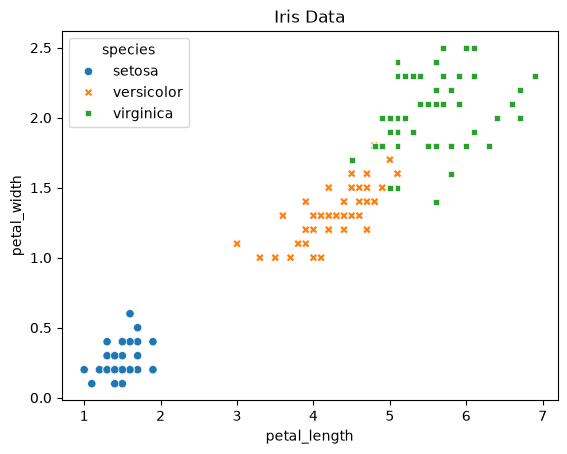

In [4]:
# Load the iris dataset
iris = sns.load_dataset('iris')

# Create a scatter plot with different species as different classes
sns.scatterplot(x='petal_length', y='petal_width', hue='species', style='species', data=iris)

# Add title
plt.title('Iris Data')
plt.show()


**Plot 2:** Change the plot to use sepal_length on the x-axis and sepal_width on the y-axis, and change the title to "Iris Sepal Dimensions"


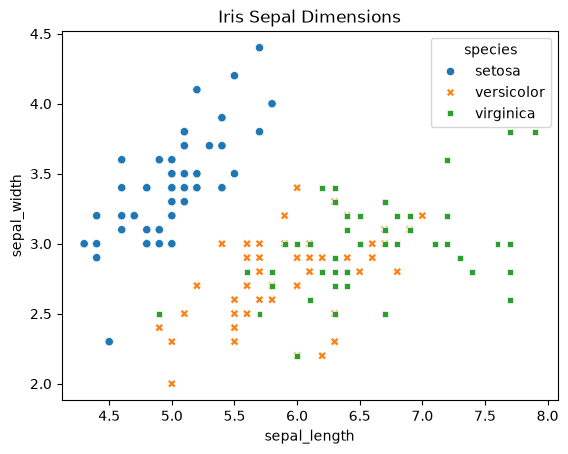

In [5]:
sns.scatterplot(x='sepal_length', y='sepal_width', hue='species', style='species', data=iris)
plt.title('Iris Sepal Dimensions')
plt.show()


##### Scatter Plot with 4 Dimensional Data


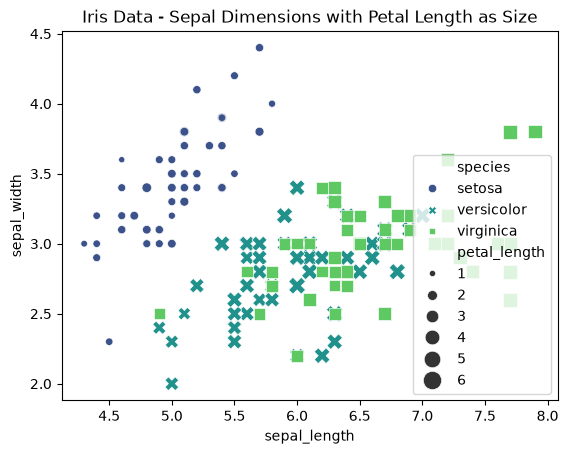

In [6]:
# Create a scatter plot with Sepal.Length vs Sepal.Width
# cex equivalent (point size) is Petal.Length and bg equivalent (background color) is Species
sns.scatterplot(x='sepal_length', y='sepal_width', hue='species', size='petal_length', data=iris, sizes=(20, 200), style='species', palette='viridis')

# Add title and show plot
plt.title('Iris Data - Sepal Dimensions with Petal Length as Size')
plt.show()


**Plot 3:** Map point size to petal_width instead of petal_length, and change the colour palette to "Set2"


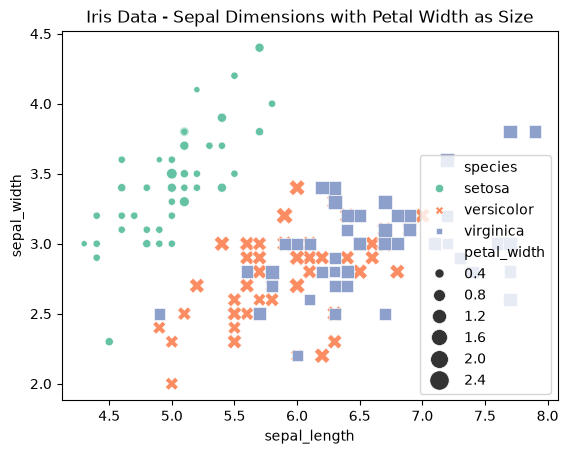

In [7]:
sns.scatterplot(
    x='sepal_length',
    y='sepal_width',
    hue='species',
    size='petal_width',
    data=iris,
    sizes=(20, 200),
    style='species',
    palette='Set2',
)
plt.title('Iris Data - Sepal Dimensions with Petal Width as Size')
plt.show()


##### Scatter plot Matrix


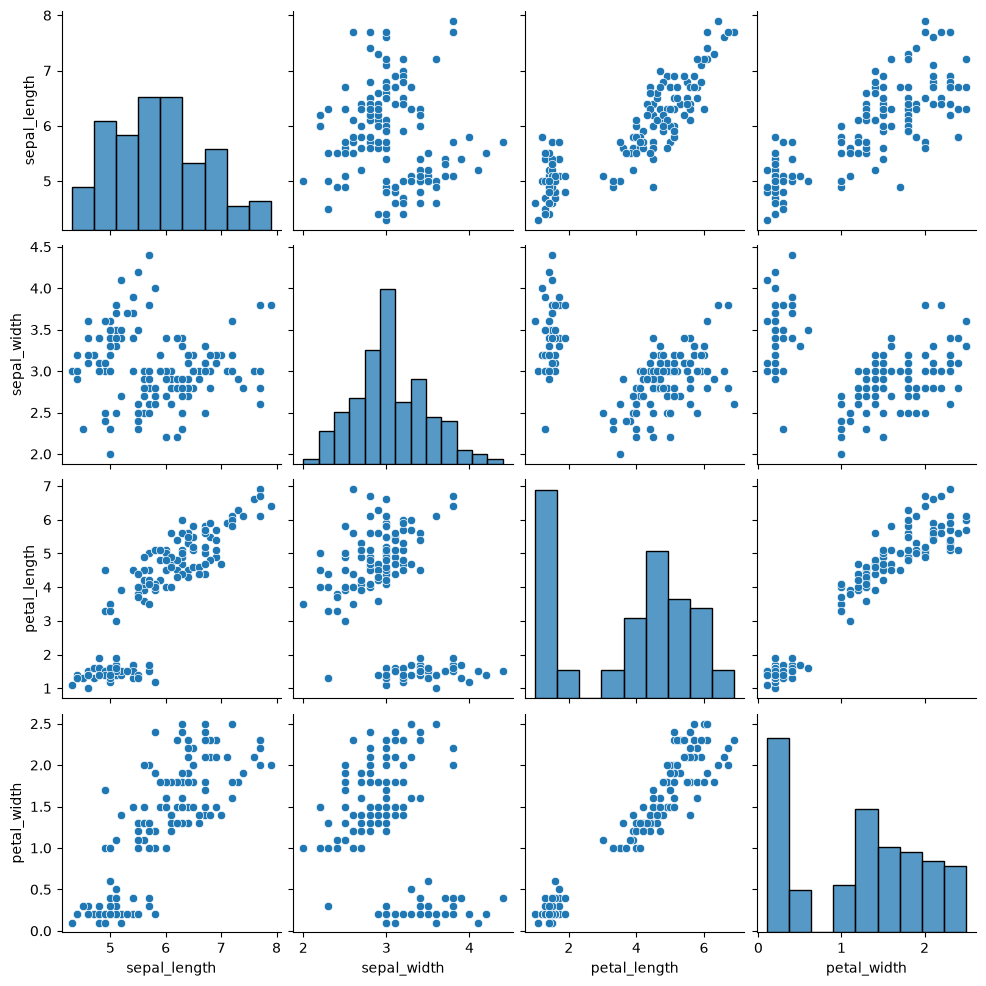

In [8]:
# Create a scatter plot matrix
sns.pairplot(iris, diag_kind='hist')

# Show the plot
plt.show()


**Plot 4:** Colour the pairplot by species with hue="species", and change the diagonal plots to KDE curves (diag_kind="kde")


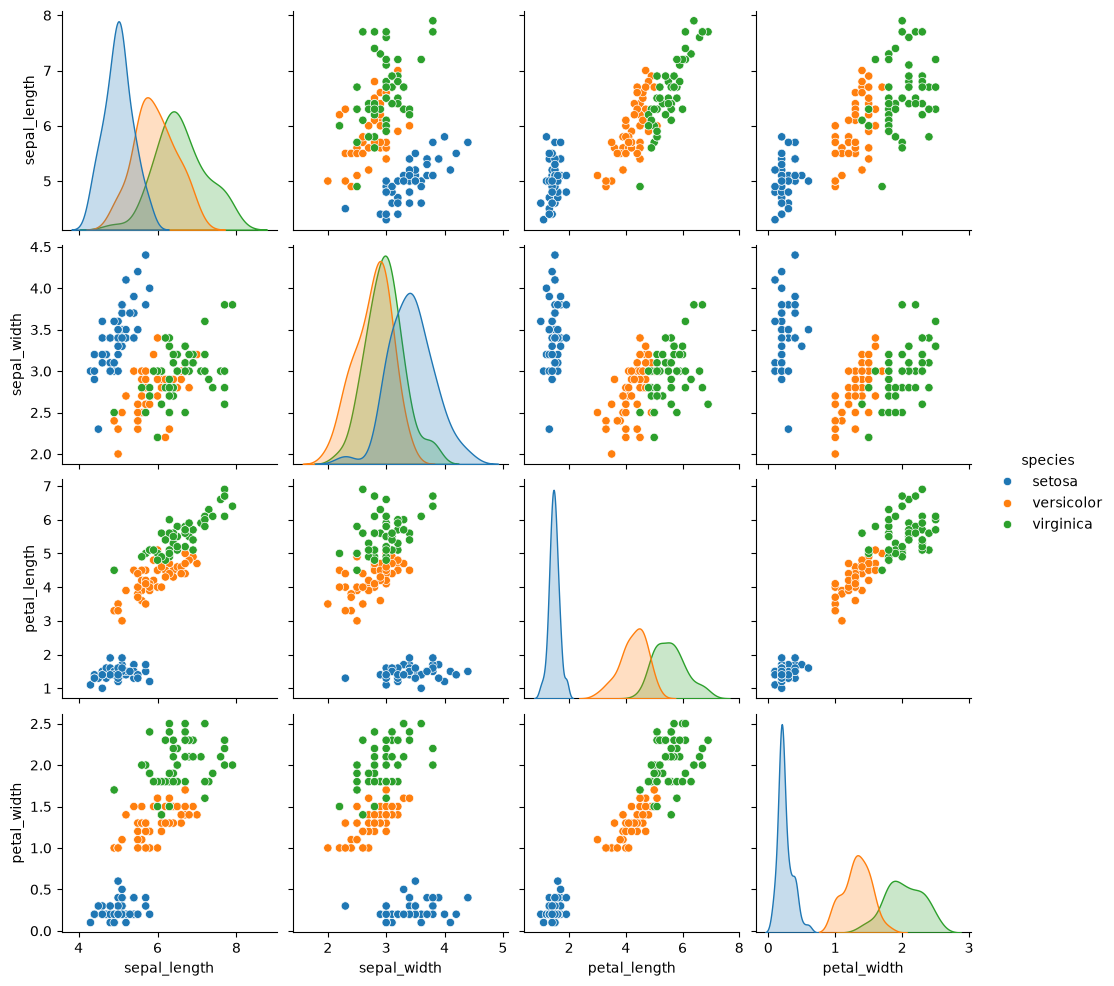

In [9]:
sns.pairplot(iris, hue='species', diag_kind='kde')
plt.show()


##### Scatter Plot Lattice


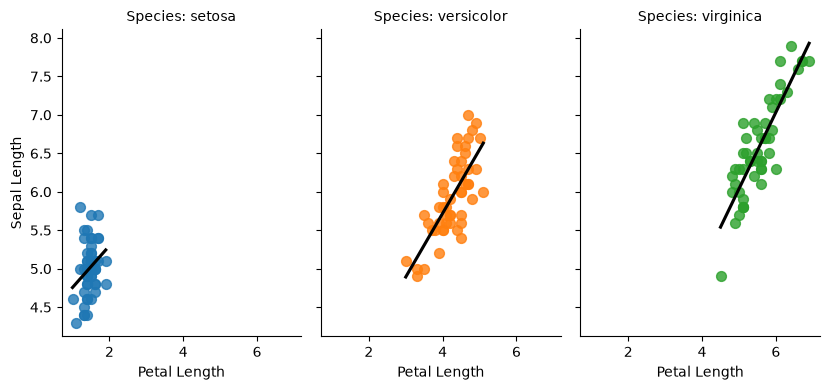

In [10]:
# Create a faceted scatter plot lattice with a smoothing line
g = sns.lmplot(x='petal_length', y='sepal_length', col='species', hue='species', data=iris,
               height=4, aspect=0.7, scatter_kws={'s': 50}, line_kws={'color': 'black'}, ci=None)

# Customize the scales and titles
g.set_axis_labels('Petal Length', 'Sepal Length')
g.set_titles('Species: {col_name}')

# Show the plot
plt.show()


**Plot 5:** Swap the axes so x is sepal_length and y is petal_length, and change the smooth line colour to red


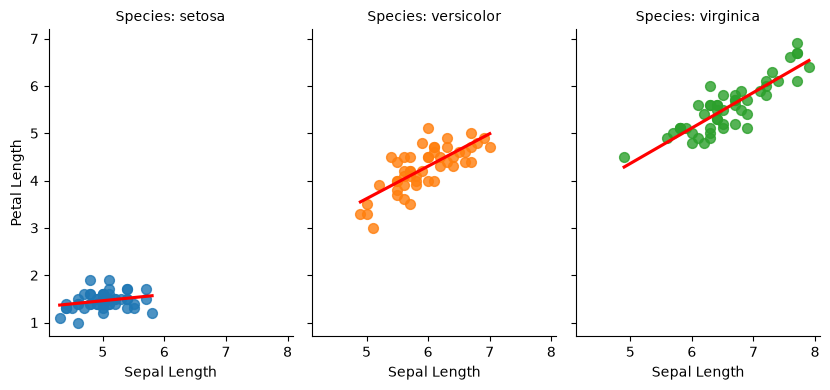

In [11]:
g = sns.lmplot(
    x='sepal_length',
    y='petal_length',
    col='species',
    hue='species',
    data=iris,
    height=4,
    aspect=0.7,
    scatter_kws={'s': 50},
    line_kws={'color': 'red'},
    ci=None,
)
g.set_axis_labels('Sepal Length', 'Petal Length')
g.set_titles('Species: {col_name}')
plt.show()


##### Parallel Axes


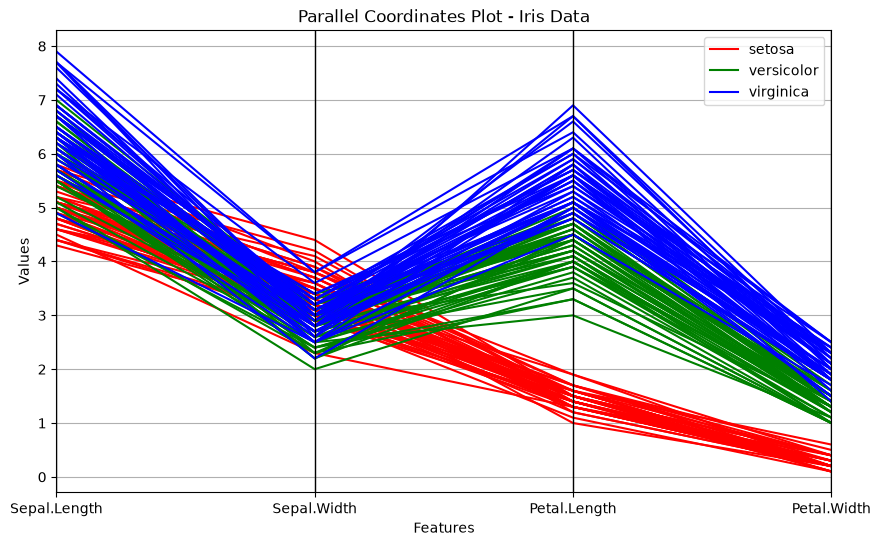

In [12]:
# Load the iris dataset
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/iris.csv"
iris = pd.read_csv(url)

# Parallel coordinates plot
plt.figure(figsize=(10, 6))
parallel_coordinates(iris, 'Species', cols=['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width'], color=['r', 'g', 'b'])

# Add title and show the plot
plt.title('Parallel Coordinates Plot - Iris Data')
plt.xlabel('Features')
plt.ylabel('Values')
plt.show()


**Plot 6:** Change the parallel coordinates colours to ["purple", "orange", "cyan"], and change the title to "Iris Parallel Coordinates (Custom Colours)"


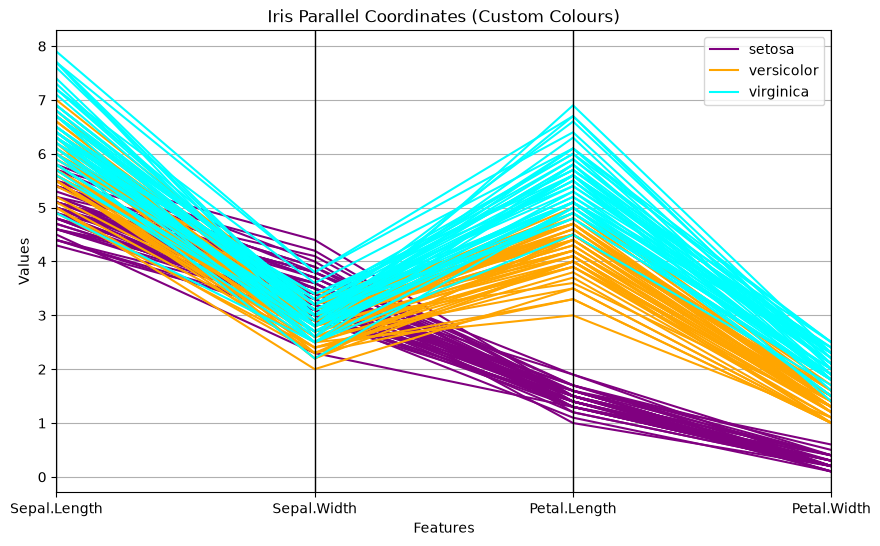

In [13]:
plt.figure(figsize=(10, 6))
parallel_coordinates(
    iris,
    'Species',
    cols=['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width'],
    color=['purple', 'orange', 'cyan'],
)
plt.title('Iris Parallel Coordinates (Custom Colours)')
plt.xlabel('Features')
plt.ylabel('Values')
plt.show()


##### Chernoff Faces
##### Things to run
### - pip install ChernoffFace
### - ModuleNotFoundError: No module named 'pkg_resources' --> pip install setuptools


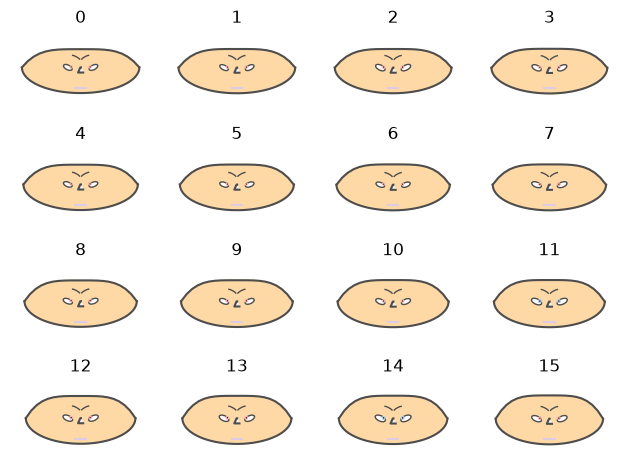

In [14]:
# Load the Longley dataset from the URL
url = "https://github.com/vincentarelbundock/Rdatasets/raw/master/csv/datasets/longley.csv"
data = pd.read_csv(url)

# Generate Chernoff faces with the Longley data
fig = chernoff_face(data=data, 
                    titles=[str(x) for x in list(range(len(data)))], 
                    color_mapper=plt.cm.Pastel1)

# Display
fig.tight_layout()
plt.show()


**Plot 7:** Plot Chernoff faces for only the first 9 rows of the Longley data, and change the colour mapper to plt.cm.Set3


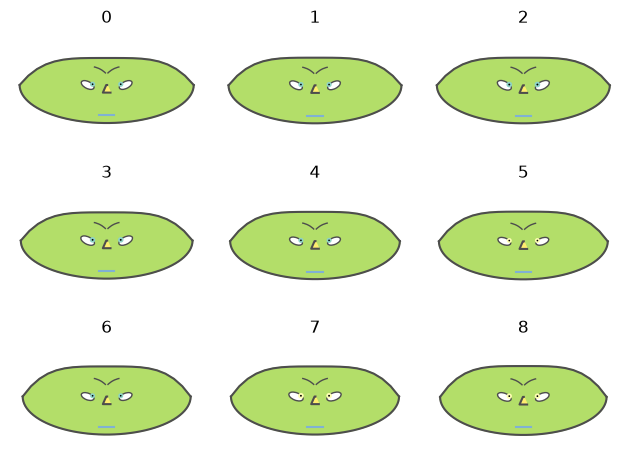

In [15]:
data9 = data.iloc[:9]
fig = chernoff_face(
    data=data9,
    titles=[str(x) for x in list(range(len(data9)))],
    color_mapper=plt.cm.Set3,
)
fig.tight_layout()
plt.show()


##### Radar Charts


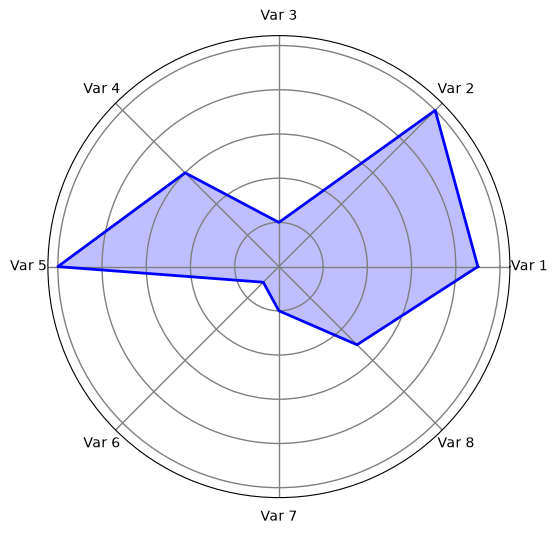

In [16]:
# Data
labels = ['Var 1', 'Var 2', 'Var 3', 'Var 4', 'Var 5', 'Var 6', 'Var 7', 'Var 8']
num_vars = len(labels)

# Create the data for the radar chart
data = [np.random.randint(0, 11) for _ in range(num_vars)]
data += data[:1]  # Close the loop by repeating the first value

# Define the angle for each axis (in radians)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop by appending the first angle

# Customize the chart (similar to R's grid line type, colors, and line width)
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Grid lines
ax.spines['polar'].set_visible(True)
ax.grid(color='gray', linestyle='-', linewidth=1)

# Fill the area under the radar chart
ax.fill(angles, data, color='blue', alpha=0.25)

# Plot the outline of the radar chart
ax.plot(angles, data, color='blue', linewidth=2, linestyle='-')

# Remove the radial labels (y-axis labels)
ax.set_yticklabels([])

# Set the ticks (labels around the radar chart)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
plt.show()


**Plot 8:** Set the random seed to 1 before creating the radar data, change the fill colour to red, and change the outline colour to darkred


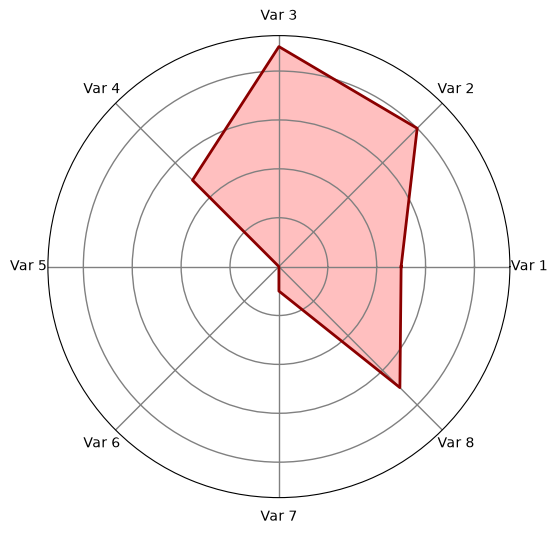

In [17]:
np.random.seed(1)
labels = ['Var 1', 'Var 2', 'Var 3', 'Var 4', 'Var 5', 'Var 6', 'Var 7', 'Var 8']
num_vars = len(labels)

data = [np.random.randint(0, 11) for _ in range(num_vars)]
data += data[:1]

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
ax.spines['polar'].set_visible(True)
ax.grid(color='gray', linestyle='-', linewidth=1)
ax.fill(angles, data, color='red', alpha=0.25)
ax.plot(angles, data, color='darkred', linewidth=2, linestyle='-')
ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
plt.show()
